# Evaluasi Pembagian Data Berbasis Waktu pada Klasifikasi Kategori ISPU DKI Jakarta
**Penyusun:** Shofia Nurul Husna (A11.2024.15957)  
**Program Studi:** Teknik Informatika – Universitas Dian Nuswantoro

Notebook ini membandingkan **Random Split** vs **Temporal Split** menggunakan **Random Forest** dan **XGBoost** pada dua dataset ISPU DKI Jakarta (2022 dan 2024–2025).

Jalankan dengan **Run All**; setiap langkah menampilkan hasilnya masing-masing.

## Langkah 0 – Import library & definisi fungsi
Sel ini hanya menyiapkan library dan fungsi-fungsi yang dipakai di langkah berikutnya (tidak menampilkan output, itu normal).

In [1]:
%matplotlib inline
"""
Eksperimen Penambangan Data:
Evaluasi Pembagian Data Berbasis Waktu pada Klasifikasi Kategori ISPU DKI Jakarta
Menggunakan Algoritma Machine Learning (Random Forest & XGBoost)

Penyusun: Shofia Nurul Husna (A11.2024.15957)
Program Studi Teknik Informatika - Universitas Dian Nuswantoro
"""

import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, TimeSeriesSplit
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 300
sns.set_theme(style="whitegrid", palette="muted")

OUTPUT_DIR = "hasil_eksperimen"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ==============================================================================
# 1. FUNGSI PEMBACAAN & PREPROCESSING DATASET
# ==============================================================================

def load_html_xls(filepath):
    """Membaca file .xls dari Jakarta Open Data yang berformat tabel HTML."""
    dfs = pd.read_html(filepath)
    return dfs[0]


def preprocess_dataset_2022(filepath):
    """
    Preprocessing Dataset 1: ISPU DKI Jakarta Tahun 2022 (365 baris)
    Kolom asli: periode_data, tanggal, pm_10, pm_duakomalima, so2, co, o3, no2, max, critical, categori, lokasi_spku
    """
    print("\n" + "="*80)
    print("PREPROCESSING DATASET 1: ISPU TAHUN 2022")
    print("="*80)
    df = load_html_xls(filepath)
    print(f"Jumlah baris awal: {len(df)}")

    # 1. Standarisasi nama kolom
    df = df.rename(columns={
        'pm_10': 'pm10',
        'pm_duakomalima': 'pm25',
        'categori': 'kategori',
        'lokasi_spku': 'stasiun',
        'critical': 'parameter_kritis'
    })

    # 2. Perbaikan inkonsistensi format tanggal:
    # - Terdapat nilai serial Excel '44926.625' -> 2022-12-31
    # - Terdapat 28 baris di periode_data=202202 yang tertulis tahun '2020-02-XX' (salah ketik tahun pada sumber data)
    def parse_date_2022(row):
        val_str = str(row['tanggal']).strip()
        periode_str = str(row['periode_data']).strip()
        year_from_periode = int(periode_str[:4])
        month_from_periode = int(periode_str[4:6])

        if re.match(r'^\d{4}-\d{2}-\d{2}$', val_str):
            dt = pd.to_datetime(val_str)
            # Koreksi tahun jika tidak sesuai dengan periode_data (misal 2020-02 menjadi 2022-02)
            if dt.year != year_from_periode:
                dt = dt.replace(year=year_from_periode, month=month_from_periode)
            return dt
        try:
            serial = float(val_str)
            return pd.to_datetime('1899-12-30') + pd.to_timedelta(int(serial), unit='D')
        except Exception:
            return pd.NaT

    df['tanggal_dt'] = df.apply(parse_date_2022, axis=1)
    print(f"Tanggal berhasil dikonversi & disinkronkan dengan periode_data. Rentang waktu: {df['tanggal_dt'].min().date()} s/d {df['tanggal_dt'].max().date()}")

    # 3. Standarisasi nama stasiun
    df['stasiun'] = df['stasiun'].astype(str).str.strip().str.upper()
    df.loc[~df['stasiun'].str.startswith('DKI'), 'stasiun'] = 'DKI4'  # Imputasi modus untuk 1 data bernilai '0'

    # 4. Konversi fitur polutan & max ke numerik
    pollutant_cols = ['pm10', 'pm25', 'so2', 'co', 'o3', 'no2']
    for col in pollutant_cols + ['max']:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # 5. Pembersihan kategori target
    df['kategori'] = df['kategori'].astype(str).str.strip().str.upper()
    valid_cats = ['BAIK', 'SEDANG', 'TIDAK SEHAT', 'SANGAT TIDAK SEHAT', 'BERBAHAYA']
    df = df[df['kategori'].isin(valid_cats)].copy()

    # 6. Hapus duplikat jika ada & urutkan berdasarkan waktu secara kronologis
    before_dedup = len(df)
    df = df.drop_duplicates().copy()
    print(f"Duplikat dihapus: {before_dedup - len(df)} baris")

    df = df.sort_values(by=['tanggal_dt', 'stasiun']).reset_index(drop=True)
    print(f"Jumlah baris akhir siap eksperimen: {len(df)}")
    print("Distribusi Kelas Target (2022):")
    print(df['kategori'].value_counts())

    return df


def preprocess_dataset_2024_2025(filepath):
    """
    Preprocessing Dataset 2: ISPU DKI Jakarta Tahun 2024-2025 (3.501 baris)
    Kolom asli: periode_data, bulan, tanggal, stasiun, pm_sepuluh, pm_duakomalima,
                sulfur_dioksida, karbon_monoksida, ozon, nitrogen_dioksida, max,
                parameter_pencemar_kritis, kategori
    """
    print("\n" + "="*80)
    print("PREPROCESSING DATASET 2: ISPU TAHUN 2024 - 2025")
    print("="*80)
    df = load_html_xls(filepath)
    print(f"Jumlah baris awal: {len(df)}")

    # 1. Standarisasi nama kolom
    df = df.rename(columns={
        'pm_sepuluh': 'pm10',
        'pm_duakomalima': 'pm25',
        'sulfur_dioksida': 'so2',
        'karbon_monoksida': 'co',
        'ozon': 'o3',
        'nitrogen_dioksida': 'no2',
        'parameter_pencemar_kritis': 'parameter_kritis'
    })

    # 2. Pembentukan kolom datetime kronologis dari periode_data (YYYYMM), bulan, dan tanggal (hari)
    years = df['periode_data'].astype(str).str[:4].astype(int)
    months = pd.to_numeric(df['bulan'], errors='coerce').fillna(
        df['periode_data'].astype(str).str[4:6].astype(int)
    ).astype(int)
    days = pd.to_numeric(df['tanggal'], errors='coerce').astype(int)

    df['tanggal_dt'] = pd.to_datetime(
        {'year': years, 'month': months, 'day': days},
        errors='coerce'
    )
    df = df.dropna(subset=['tanggal_dt']).copy()
    print(f"Tanggal berhasil dikonversi. Rentang waktu: {df['tanggal_dt'].min().date()} s/d {df['tanggal_dt'].max().date()}")

    # 3. Standarisasi penulisan nama stasiun (mengatasi spasi ganda & variasi nama)
    def clean_station(s):
        s = str(s).upper().strip()
        if 'DKI1' in s:
            return 'DKI1 BUNDARAN HI'
        elif 'DKI2' in s:
            return 'DKI2 KELAPA GADING'
        elif 'DKI3' in s:
            return 'DKI3 JAGAKARSA'
        elif 'DKI4' in s:
            return 'DKI4 LUBANG BUAYA'
        elif 'DKI5' in s:
            return 'DKI5 KEBON JERUK'
        return s

    df['stasiun'] = df['stasiun'].apply(clean_station)
    print("Stasiun setelah standarisasi:", df['stasiun'].value_counts().to_dict())

    # 4. Konversi fitur polutan & max ke numerik ('N/A' otomatis menjadi NaN)
    pollutant_cols = ['pm10', 'pm25', 'so2', 'co', 'o3', 'no2']
    for col in pollutant_cols + ['max']:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    print("Jumlah Missing Values (NaN) per fitur polutan:")
    print(df[pollutant_cols + ['max']].isna().sum().to_dict())

    # 5. Pembersihan kategori target (hapus 'TIDAK ADA DATA', 'N/A', dan kelas dengan sampel = 1 agar dapat dievaluasi di kedua split)
    df['kategori'] = df['kategori'].astype(str).str.strip().str.upper()
    print("Distribusi Kategori Sebelum Filter:", df['kategori'].value_counts().to_dict())

    # Filter hanya kelas valid yang memiliki jumlah sampel memadai (BAIK, SEDANG, TIDAK SEHAT)
    # Catatan: 'SANGAT TIDAK SEHAT' hanya 1 baris dari 3501 baris sehingga tidak bisa dibagi ke train & test sekaligus
    valid_cats = ['BAIK', 'SEDANG', 'TIDAK SEHAT']
    df = df[df['kategori'].isin(valid_cats)].copy()

    # 6. Hapus duplikat & urutkan berdasarkan waktu secara kronologis
    before_dedup = len(df)
    df = df.drop_duplicates(subset=['tanggal_dt', 'stasiun', 'pm10', 'pm25', 'so2', 'co', 'o3', 'no2']).copy()
    print(f"Duplikat dihapus: {before_dedup - len(df)} baris")

    df = df.sort_values(by=['tanggal_dt', 'stasiun']).reset_index(drop=True)
    print(f"Jumlah baris akhir siap eksperimen: {len(df)}")
    print("Distribusi Kelas Target (2024-2025):")
    print(df['kategori'].value_counts())

    return df


# ==============================================================================
# 2. FUNGSI ANALISIS AUTOKORELASI DERET WAKTU
# ==============================================================================

def analyze_autocorrelation(df, dataset_name):
    """Menghitung autokorelasi lag-1 s/d lag-7 untuk membuktikan ketergantungan temporal."""
    pollutant_cols = ['pm10', 'pm25', 'so2', 'co', 'o3', 'no2']
    records = []

    # Hitung rata-rata harian lintas stasiun untuk deret waktu harian murni
    daily_df = df.groupby('tanggal_dt')[pollutant_cols].mean().sort_index()

    for col in pollutant_cols:
        series = daily_df[col].dropna()
        records.append({
            'Dataset': dataset_name,
            'Parameter': col.upper(),
            'Lag_1_Hari': series.autocorr(lag=1),
            'Lag_2_Hari': series.autocorr(lag=2),
            'Lag_3_Hari': series.autocorr(lag=3),
            'Lag_7_Hari': series.autocorr(lag=7)
        })
    return pd.DataFrame(records)


# ==============================================================================
# 3. FUNGSI EKSPERIMEN PEMODELAN & EVALUASI
# ==============================================================================

def evaluate_predictions(y_true, y_pred, labels):
    """Menghitung metrik evaluasi komprehensif (Accuracy, Precision, Recall, F1 Macro & Weighted)."""
    return {
        'Accuracy': accuracy_score(y_true, y_pred) * 100,
        'Precision_Macro': precision_score(y_true, y_pred, labels=labels, average='macro', zero_division=0) * 100,
        'Recall_Macro': recall_score(y_true, y_pred, labels=labels, average='macro', zero_division=0) * 100,
        'F1_Macro': f1_score(y_true, y_pred, labels=labels, average='macro', zero_division=0) * 100,
        'F1_Weighted': f1_score(y_true, y_pred, labels=labels, average='weighted', zero_division=0) * 100,
    }


def add_temporal_lag_features(df):
    """
    Membuat skenario Prediksi Hari Berikutnya (Next-Day Forecasting / t+1):
    Fitur adalah nilai polutan pada hari t, sedangkan Target adalah Kategori ISPU pada hari t+1
    di stasiun yang sama. Skenario ini menguji dampak autokorelasi deret waktu ketika
    aturan deterministik hari yang sama tidak lagi berlaku.
    """
    df_lag = df.sort_values(['stasiun', 'tanggal_dt']).copy()
    pollutant_cols = ['pm10', 'pm25', 'so2', 'co', 'o3', 'no2']
    # Tambahkan fitur rata-rata bergerak 3 hari sebelumnya & lag-1
    for col in pollutant_cols:
        df_lag[f'{col}_lag1'] = df_lag.groupby('stasiun')[col].shift(1)
        df_lag[f'{col}_roll3'] = df_lag.groupby('stasiun')[col].transform(lambda s: s.rolling(3, min_periods=1).mean())
    # Target adalah kategori hari esok (t+1)
    df_lag['kategori_besok'] = df_lag.groupby('stasiun')['kategori'].shift(-1)
    df_lag = df_lag.dropna(subset=['kategori_besok']).sort_values(['tanggal_dt', 'stasiun']).reset_index(drop=True)
    return df_lag


def run_experiments_on_dataset(df, dataset_label):
    """
    Menjalankan matriks eksperimen lengkap:
    - 2 Algoritma: Random Forest vs XGBoost
    - 2 Skema Split Utama: Random Split (80:20 Stratified) vs Temporal Split (80:20 Berurutan Waktu)
    - Cross-Validation: 5-Fold Stratified K-Fold vs 5-Fold TimeSeriesSplit
    - 3 Skenario Fitur/Tugas:
        (A) Klasifikasi 6 Parameter Polutan Murni (PM10, PM2.5, SO2, CO, O3, NO2) -> Tanpa 'max'
        (B) Klasifikasi 6 Parameter Polutan + Fitur 'max' (Uji Efek Data Leakage Deterministik)
        (C) Prediksi Kategori ISPU Hari Berikutnya (t+1) dari Polutan Hari Ini (Uji Efek Autokorelasi Temporal)
    """
    results = []
    cm_store = {}

    pollutant_cols = ['pm10', 'pm25', 'so2', 'co', 'o3', 'no2']

    scenarios = [
        ('Skenario A: 6 Parameter Polutan (Tanpa Max)', df, pollutant_cols, 'kategori'),
        ('Skenario B: 6 Polutan + Fitur Max (Uji Data Leakage)', df, pollutant_cols + ['max'], 'kategori'),
    ]

    # Tambahkan Skenario C (Prediksi H+1) untuk menguji efek autokorelasi deret waktu secara nyata
    df_nextday = add_temporal_lag_features(df)
    lag_features = pollutant_cols + [f'{c}_lag1' for c in pollutant_cols] + [f'{c}_roll3' for c in pollutant_cols]
    scenarios.append(('Skenario C: Prediksi Kategori H+1 (Uji Autokorelasi)', df_nextday, lag_features, 'kategori_besok'))

    for scen_name, data_scen, feat_cols, target_col in scenarios:
        le = LabelEncoder()
        y_all = le.fit_transform(data_scen[target_col])
        label_indices = np.arange(len(le.classes_))
        X_all = data_scen[feat_cols].copy()

        # 1. Pembagian Acak (Random Stratified Split 80:20)
        X_tr_rand, X_te_rand, y_tr_rand, y_te_rand = train_test_split(
            X_all, y_all, test_size=0.20, random_state=42, stratify=y_all
        )

        # 2. Pembagian Berurutan Waktu (Temporal Split 80:20)
        # Data sudah diurutkan secara kronologis berdasarkan tanggal_dt
        split_idx = int(len(data_scen) * 0.80)
        X_tr_temp, X_te_temp = X_all.iloc[:split_idx], X_all.iloc[split_idx:]
        y_tr_temp, y_te_temp = y_all[:split_idx], y_all[split_idx:]

        split_configs = [
            ('Random Split (80:20)', X_tr_rand, X_te_rand, y_tr_rand, y_te_rand),
            ('Temporal Split (80:20)', X_tr_temp, X_te_temp, y_tr_temp, y_te_temp),
        ]

        models = {
            'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
            'XGBoost': XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42, eval_metric='mlogloss')
        }

        for model_name, model_proto in models.items():
            for split_name, X_tr, X_te, y_tr, y_te in split_configs:
                # Imputasi nilai hilang menggunakan Median yang dihitung HANYA dari data latih (mencegah data leakage)
                imputer = SimpleImputer(strategy='median')
                X_tr_imp = imputer.fit_transform(X_tr)
                X_te_imp = imputer.transform(X_te)

                # Latih model
                if model_name == 'Random Forest':
                    clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
                else:
                    clf = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42, eval_metric='mlogloss')

                clf.fit(X_tr_imp, y_tr)
                y_pred_tr = clf.predict(X_tr_imp)
                y_pred_te = clf.predict(X_te_imp)

                metrics_tr = evaluate_predictions(y_tr, y_pred_tr, label_indices)
                metrics_te = evaluate_predictions(y_te, y_pred_te, label_indices)

                results.append({
                    'Dataset': dataset_label,
                    'Skenario': scen_name,
                    'Algoritma': model_name,
                    'Skema_Split': split_name,
                    'Train_Accuracy': round(metrics_tr['Accuracy'], 2),
                    'Test_Accuracy': round(metrics_te['Accuracy'], 2),
                    'Precision_Macro': round(metrics_te['Precision_Macro'], 2),
                    'Recall_Macro': round(metrics_te['Recall_Macro'], 2),
                    'F1_Macro': round(metrics_te['F1_Macro'], 2),
                    'F1_Weighted': round(metrics_te['F1_Weighted'], 2),
                })

                # Simpan confusion matrix untuk Skenario A
                if 'Skenario A' in scen_name:
                    cm = confusion_matrix(y_te, y_pred_te, labels=label_indices)
                    cm_store[(dataset_label, model_name, split_name)] = (cm, le.classes_)

            # Evaluasi Cross-Validation (5-Fold Random vs 5-Fold TimeSeriesSplit) pada Skenario A & C
            if 'Skenario A' in scen_name or 'Skenario C' in scen_name:
                for cv_name, cv_splitter in [
                    ('5-Fold Stratified CV (Random)', StratifiedKFold(n_splits=5, shuffle=True, random_state=42)),
                    ('5-Fold TimeSeriesSplit (Temporal)', TimeSeriesSplit(n_splits=5))
                ]:
                    fold_accs, fold_f1s = [], []
                    for tr_idx, te_idx in cv_splitter.split(X_all, y_all):
                        # Pastikan semua kelas ada di y_train untuk XGBoost
                        if len(np.unique(y_all[tr_idx])) < len(label_indices):
                            # Mapping ulang kelas lokal jika ada kelas yang belum muncul di awal periode
                            le_fold = LabelEncoder()
                            y_tr_f = le_fold.fit_transform(y_all[tr_idx])
                            valid_te_mask = np.isin(y_all[te_idx], le_fold.classes_)
                            if valid_te_mask.sum() == 0:
                                continue
                            X_tr_f = X_all.iloc[tr_idx]
                            X_te_f = X_all.iloc[te_idx][valid_te_mask]
                            y_te_f = le_fold.transform(y_all[te_idx][valid_te_mask])
                        else:
                            X_tr_f, X_te_f = X_all.iloc[tr_idx], X_all.iloc[te_idx]
                            y_tr_f, y_te_f = y_all[tr_idx], y_all[te_idx]

                        imp_f = SimpleImputer(strategy='median')
                        X_tr_f_imp = imp_f.fit_transform(X_tr_f)
                        X_te_f_imp = imp_f.transform(X_te_f)

                        if model_name == 'Random Forest':
                            clf_f = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
                        else:
                            clf_f = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42, eval_metric='mlogloss')

                        clf_f.fit(X_tr_f_imp, y_tr_f)
                        preds_f = clf_f.predict(X_te_f_imp)
                        fold_accs.append(accuracy_score(y_te_f, preds_f) * 100)
                        fold_f1s.append(f1_score(y_te_f, preds_f, average='macro', zero_division=0) * 100)

                    results.append({
                        'Dataset': dataset_label,
                        'Skenario': scen_name,
                        'Algoritma': model_name,
                        'Skema_Split': cv_name,
                        'Train_Accuracy': np.nan,
                        'Test_Accuracy': round(np.mean(fold_accs), 2),
                        'Precision_Macro': np.nan,
                        'Recall_Macro': np.nan,
                        'F1_Macro': round(np.mean(fold_f1s), 2),
                        'F1_Weighted': round(np.std(fold_accs), 2),  # Gunakan kolom ini untuk mencatat Std Dev CV
                    })

    return pd.DataFrame(results), cm_store


# ==============================================================================
# 4. FUNGSI PEMBUATAN VISUALISASI GRAFIK
# ==============================================================================

def generate_visualizations(df_2022, df_2024, autocorr_df, results_df, cm_store):
    """Menghasilkan grafik beresolusi tinggi untuk laporan penelitian."""

    # 1. Grafik Distribusi Kategori ISPU pada Kedua Dataset
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for ax, (df_curr, title) in zip(axes, [
        (df_2022, 'Dataset 1: ISPU Tahun 2022 (n = 365)'),
        (df_2024, f'Dataset 2: ISPU Tahun 2024–2025 (n = {len(df_2024)})')
    ]):
        counts = df_curr['kategori'].value_counts()
        bars = sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='viridis')
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.set_xlabel('Kategori ISPU')
        ax.set_ylabel('Jumlah Hari / Observasi')
        for p in bars.patches:
            ax.annotate(f'{int(p.get_height())}',
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=9, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, '1_distribusi_kelas_ispu.png'))
    plt.show()

    # 2. Grafik Autokorelasi Deret Waktu Parameter Pencemar (Lag 1, 2, 3, 7 Hari)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for ax, ds_name in zip(axes, ['Dataset 2022', 'Dataset 2024-2025']):
        sub = autocorr_df[autocorr_df['Dataset'] == ds_name].melt(
            id_vars=['Parameter'],
            value_vars=['Lag_1_Hari', 'Lag_2_Hari', 'Lag_3_Hari', 'Lag_7_Hari'],
            var_name='Lag_Waktu', value_name='Koefisien_Autokorelasi'
        )
        sub['Lag_Waktu'] = sub['Lag_Waktu'].str.replace('_', ' ')
        sns.barplot(data=sub, x='Parameter', y='Koefisien_Autokorelasi', hue='Lag_Waktu', ax=ax, palette='rocket')
        ax.set_title(f'Autokorelasi Parameter Pencemar ({ds_name})', fontsize=11, fontweight='bold')
        ax.set_xlabel('Parameter Pencemar Udara')
        ax.set_ylabel('Koefisien Autokorelasi (r)')
        ax.axhline(0.5, color='red', linestyle='--', linewidth=1, label='Batas Korelasi Kuat (0.5)')
        ax.legend(title='Jarak Waktu (Lag)', fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, '2_autokorelasi_temporal.png'))
    plt.show()

    # 3. Grafik Perbandingan Kinerja Random Split vs Temporal Split (80:20)
    sub_8020 = results_df[results_df['Skema_Split'].isin(['Random Split (80:20)', 'Temporal Split (80:20)'])].copy()
    sub_8020['Model_Split'] = sub_8020['Algoritma'] + '\n(' + sub_8020['Skema_Split'].str.replace(' (80:20)', '') + ')'

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
    for ax, ds_name in zip(axes, ['Dataset 2022', 'Dataset 2024-2025']):
        ds_sub = sub_8020[sub_8020['Dataset'] == ds_name]
        sns.barplot(
            data=ds_sub, x='Skenario', y='Test_Accuracy', hue='Model_Split', ax=ax, palette='Set2'
        )
        ax.set_title(f'Perbandingan Akurasi Uji: Random vs Temporal Split\n({ds_name})', fontsize=11, fontweight='bold')
        ax.set_xlabel('')
        ax.set_ylabel('Akurasi Data Uji (%)')
        ax.set_xticklabels(['Skenario A\n(6 Polutan Murni)', 'Skenario B\n(+ Fitur Max)', 'Skenario C\n(Prediksi H+1)'])
        ax.set_ylim(40, 105)
        for p in ax.patches:
            h = p.get_height()
            if h > 0:
                ax.annotate(f'{h:.1f}%',
                            (p.get_x() + p.get_width() / 2., h),
                            ha='center', va='bottom', fontsize=7.5, fontweight='bold', rotation=0)
        ax.legend(title='Algoritma & Skema Split', fontsize=8, loc='lower left')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, '3_perbandingan_akurasi_split.png'))
    plt.show()

    # 4. Grafik Perbandingan F1-Macro pada Skenario A & C
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
    for ax, ds_name in zip(axes, ['Dataset 2022', 'Dataset 2024-2025']):
        ds_sub = sub_8020[sub_8020['Dataset'] == ds_name]
        sns.barplot(
            data=ds_sub, x='Skenario', y='F1_Macro', hue='Model_Split', ax=ax, palette='Paired'
        )
        ax.set_title(f'Perbandingan F1-Macro: Random vs Temporal Split\n({ds_name})', fontsize=11, fontweight='bold')
        ax.set_xlabel('')
        ax.set_ylabel('F1-Macro Data Uji (%)')
        ax.set_xticklabels(['Skenario A\n(6 Polutan Murni)', 'Skenario B\n(+ Fitur Max)', 'Skenario C\n(Prediksi H+1)'])
        ax.set_ylim(20, 108)
        for p in ax.patches:
            h = p.get_height()
            if h > 0:
                ax.annotate(f'{h:.1f}%',
                            (p.get_x() + p.get_width() / 2., h),
                            ha='center', va='bottom', fontsize=7.5, fontweight='bold')
        ax.legend(title='Algoritma & Skema Split', fontsize=8, loc='lower left')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, '4_perbandingan_f1_macro_split.png'))
    plt.show()

    # 5. Confusion Matrix untuk Dataset 2024-2025 (Skenario A: 6 Polutan Murni)
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    configs = [
        ('Random Forest', 'Random Split (80:20)', axes[0, 0]),
        ('Random Forest', 'Temporal Split (80:20)', axes[0, 1]),
        ('XGBoost', 'Random Split (80:20)', axes[1, 0]),
        ('XGBoost', 'Temporal Split (80:20)', axes[1, 1]),
    ]
    for model_name, split_name, ax in configs:
        key = ('Dataset 2024-2025', model_name, split_name)
        if key in cm_store:
            cm, classes = cm_store[key]
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=ax)
            ax.set_title(f'{model_name} - {split_name}\n(Dataset 2024–2025, 6 Polutan)', fontsize=10, fontweight='bold')
            ax.set_xlabel('Prediksi Model')
            ax.set_ylabel('Kelas Aktual')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, '5_confusion_matrix_2024_2025.png'))
    plt.show()

    print(f"\nSeluruh grafik visualisasi berhasil disimpan di folder '{OUTPUT_DIR}/'.")


# ==============================================================================
# 5. EKSEKUSI UTAMA
# ==============================================================================

plt.rcParams['figure.dpi'] = 100
print('Library & fungsi siap digunakan.')

Library & fungsi siap digunakan.


## Langkah 1 – Load & preprocessing Dataset 2022

In [2]:
file_2022 = "indeks-standar-pencemaran-udara-(ispu)-tahun-2022-komponen-data.xls"
df_2022 = preprocess_dataset_2022(file_2022)
df_2022.head()


PREPROCESSING DATASET 1: ISPU TAHUN 2022
Jumlah baris awal: 365
Tanggal berhasil dikonversi & disinkronkan dengan periode_data. Rentang waktu: 2022-01-01 s/d 2022-12-31
Duplikat dihapus: 0 baris
Jumlah baris akhir siap eksperimen: 365
Distribusi Kelas Target (2022):
kategori
SEDANG         225
TIDAK SEHAT    137
BAIK             3
Name: count, dtype: int64


,periode_data,tanggal,pm10,pm25,so2,co,o3,no2,max,parameter_kritis,kategori,stasiun,tanggal_dt
0,202201,2022-01-01,57,85,48,13,34,18,85,"PM2,5",SEDANG,DKI4,2022-01-01
1,202201,2022-01-02,40,70,45,10,36,11,70,"PM2,5",SEDANG,DKI4,2022-01-02
2,202201,2022-01-03,49,80,49,13,37,21,80,"PM2,5",SEDANG,DKI4,2022-01-03
3,202201,2022-01-04,59,102,51,14,51,26,102,"PM2,5",TIDAK SEHAT,DKI4,2022-01-04
4,202201,2022-01-05,95,165,53,18,55,32,165,"PM2,5",TIDAK SEHAT,DKI4,2022-01-05


## Langkah 2 – Load & preprocessing Dataset 2024–2025

In [3]:
file_2024 = "data-indeks-standar-pencemar-udara-(ispu)-di-provinsi-dki-jakarta-komponen-data.xls"
df_2024 = preprocess_dataset_2024_2025(file_2024)
df_2024.head()


PREPROCESSING DATASET 2: ISPU TAHUN 2024 - 2025
Jumlah baris awal: 3501
Tanggal berhasil dikonversi. Rentang waktu: 2024-01-01 s/d 2025-11-30
Stasiun setelah standarisasi: {'DKI3 JAGAKARSA': 700, 'DKI1 BUNDARAN HI': 700, 'DKI2 KELAPA GADING': 700, 'DKI4 LUBANG BUAYA': 700, 'DKI5 KEBON JERUK': 700}
Jumlah Missing Values (NaN) per fitur polutan:
{'pm10': 263, 'pm25': 60, 'so2': 55, 'co': 49, 'o3': 45, 'no2': 68, 'max': 7}
Distribusi Kategori Sebelum Filter: {'SEDANG': 2694, 'BAIK': 444, 'TIDAK SEHAT': 341, 'TIDAK ADA DATA': 20, 'SANGAT TIDAK SEHAT': 1}
Duplikat dihapus: 0 baris
Jumlah baris akhir siap eksperimen: 3479
Distribusi Kelas Target (2024-2025):
kategori
SEDANG         2694
BAIK            444
TIDAK SEHAT     341
Name: count, dtype: int64


,periode_data,bulan,tanggal,stasiun,pm10,pm25,so2,co,o3,no2,max,parameter_kritis,kategori,tanggal_dt
0,202401,1,1,DKI1 BUNDARAN HI,64.0,89.0,52.0,9.0,13.0,30.0,89.0,PM25,SEDANG,2024-01-01
1,202401,1,1,DKI2 KELAPA GADING,67.0,103.0,34.0,18.0,26.0,NaN,103.0,PM25,TIDAK SEHAT,2024-01-01
2,202401,1,1,DKI3 JAGAKARSA,65.0,89.0,14.0,54.0,13.0,NaN,89.0,PM25,SEDANG,2024-01-01
3,202401,1,1,DKI4 LUBANG BUAYA,74.0,110.0,10.0,20.0,24.0,10.0,110.0,PM25,TIDAK SEHAT,2024-01-01
4,202401,1,1,DKI5 KEBON JERUK,58.0,99.0,40.0,18.0,55.0,12.0,99.0,PM25,SEDANG,2024-01-01


## Langkah 3 – Statistik deskriptif parameter pencemar

In [4]:
pol = ['pm10', 'pm25', 'so2', 'co', 'o3', 'no2', 'max']
print('=== Dataset 2022 ===')
display(df_2022[pol].describe().round(2))
print('=== Dataset 2024-2025 ===')
display(df_2024[pol].describe().round(2))

=== Dataset 2022 ===


,pm10,pm25,so2,co,o3,no2,max
count,365.00,365.00,365.00,365.00,365.00,365.00,365.00
mean,59.82,92.94,47.93,18.42,57.24,28.75,93.85
std,13.33,24.42,4.57,7.10,23.35,8.68,24.44
min,23.00,40.00,37.00,7.00,15.00,6.00,49.00
25%,52.00,75.00,44.00,14.00,39.00,23.00,76.00
50%,60.00,92.00,49.00,17.00,54.00,28.00,93.00
75%,68.00,111.00,51.00,21.00,71.00,34.00,111.00
max,95.00,165.00,62.00,55.00,181.00,52.00,181.00


=== Dataset 2024-2025 ===


,pm10,pm25,so2,co,o3,no2,max
count,3236.00,3439.00,3444.00,3450.00,3454.00,3431.00,3479.00
mean,48.89,71.41,36.03,15.10,23.79,27.16,73.33
std,16.55,23.21,15.88,6.83,12.80,16.40,20.87
min,5.00,10.00,3.00,2.00,2.00,1.00,14.00
25%,37.00,56.00,24.00,10.00,15.00,15.00,58.00
50%,52.00,73.00,32.00,14.00,21.00,23.00,73.00
75%,60.00,87.00,53.00,20.00,29.00,37.00,87.00
max,187.00,157.00,112.00,70.00,115.00,187.00,187.00


## Langkah 4 – Analisis autokorelasi deret waktu
Membuktikan bahwa nilai polutan hari ini mirip dengan hari-hari sebelumnya.

In [5]:
ac_2022 = analyze_autocorrelation(df_2022, 'Dataset 2022')
ac_2024 = analyze_autocorrelation(df_2024, 'Dataset 2024-2025')
autocorr_df = pd.concat([ac_2022, ac_2024], ignore_index=True)
autocorr_df.round(3)

,Dataset,Parameter,Lag_1_Hari,Lag_2_Hari,Lag_3_Hari,Lag_7_Hari
0,Dataset 2022,PM10,0.527,0.377,0.261,0.178
1,Dataset 2022,PM25,0.479,0.341,0.235,0.145
2,Dataset 2022,SO2,0.761,0.709,0.652,0.649
3,Dataset 2022,CO,0.491,0.413,0.287,0.056
4,Dataset 2022,O3,0.764,0.644,0.590,0.547
5,Dataset 2022,NO2,0.514,0.330,0.184,-0.007
6,Dataset 2024-2025,PM10,0.709,0.609,0.574,0.466
7,Dataset 2024-2025,PM25,0.723,0.648,0.616,0.505
8,Dataset 2024-2025,SO2,0.936,0.905,0.882,0.806
9,Dataset 2024-2025,CO,0.537,0.429,0.447,0.301


## Langkah 5 – Eksperimen pada Dataset 2022
Skenario A (6 polutan), B (+ fitur max), C (prediksi H+1) × Random Forest & XGBoost × skema split.

In [6]:
res_2022, cm_2022 = run_experiments_on_dataset(df_2022, 'Dataset 2022')
res_2022

,Dataset,Skenario,Algoritma,Skema_Split,Train_Accuracy,Test_Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted
0,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,Random Split (80:20),100.0,98.63,65.94,66.67,66.30,97.95
1,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,Temporal Split (80:20),100.0,98.63,66.67,66.15,66.41,99.31
2,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,5-Fold Stratified CV (Random),NaN,98.90,NaN,NaN,85.93,1.03
3,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,5-Fold TimeSeriesSplit (Temporal),NaN,98.33,NaN,NaN,91.86,2.58
4,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),XGBoost,Random Split (80:20),100.0,100.00,100.00,100.00,100.00,100.00
5,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),XGBoost,Temporal Split (80:20),100.0,95.89,66.67,65.13,65.88,97.90
6,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),XGBoost,5-Fold Stratified CV (Random),NaN,98.36,NaN,NaN,85.54,1.03
7,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),XGBoost,5-Fold TimeSeriesSplit (Temporal),NaN,97.67,NaN,NaN,78.35,2.26
8,Dataset 2022,Skenario B: 6 Polutan + Fitur Max (Uji Data Le...,Random Forest,Random Split (80:20),100.0,98.63,65.94,66.67,66.30,97.95
9,Dataset 2022,Skenario B: 6 Polutan + Fitur Max (Uji Data Le...,Random Forest,Temporal Split (80:20),100.0,98.63,66.67,66.15,66.41,99.31


## Langkah 6 – Eksperimen pada Dataset 2024–2025 (±1–2 menit)

In [7]:
res_2024, cm_2024 = run_experiments_on_dataset(df_2024, 'Dataset 2024-2025')
res_2024

,Dataset,Skenario,Algoritma,Skema_Split,Train_Accuracy,Test_Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted
0,Dataset 2024-2025,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,Random Split (80:20),99.46,98.28,97.85,96.53,97.18,98.27
1,Dataset 2024-2025,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,Temporal Split (80:20),99.25,99.71,99.88,98.96,99.41,99.71
2,Dataset 2024-2025,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,5-Fold Stratified CV (Random),NaN,97.64,NaN,NaN,96.25,0.33
3,Dataset 2024-2025,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,5-Fold TimeSeriesSplit (Temporal),NaN,97.10,NaN,NaN,92.36,1.94
4,Dataset 2024-2025,Skenario A: 6 Parameter Polutan (Tanpa Max),XGBoost,Random Split (80:20),99.46,98.13,97.20,96.78,96.98,98.13
5,Dataset 2024-2025,Skenario A: 6 Parameter Polutan (Tanpa Max),XGBoost,Temporal Split (80:20),99.25,100.00,100.00,100.00,100.00,100.00
6,Dataset 2024-2025,Skenario A: 6 Parameter Polutan (Tanpa Max),XGBoost,5-Fold Stratified CV (Random),NaN,97.70,NaN,NaN,96.34,0.65
7,Dataset 2024-2025,Skenario A: 6 Parameter Polutan (Tanpa Max),XGBoost,5-Fold TimeSeriesSplit (Temporal),NaN,97.24,NaN,NaN,91.88,1.57
8,Dataset 2024-2025,Skenario B: 6 Polutan + Fitur Max (Uji Data Le...,Random Forest,Random Split (80:20),99.46,99.14,98.58,98.58,98.58,99.14
9,Dataset 2024-2025,Skenario B: 6 Polutan + Fitur Max (Uji Data Le...,Random Forest,Temporal Split (80:20),99.25,100.00,100.00,100.00,100.00,100.00


## Langkah 7 – Selisih kinerja Random Split vs Temporal Split (80:20)

In [8]:
results_df = pd.concat([res_2022, res_2024], ignore_index=True)
sub = results_df[results_df['Skema_Split'].isin(['Random Split (80:20)', 'Temporal Split (80:20)'])]
pivot_df = sub.pivot_table(index=['Dataset', 'Skenario', 'Algoritma'], columns='Skema_Split',
                           values=['Test_Accuracy', 'F1_Macro'])
pivot_df['Selisih_Akurasi'] = (pivot_df[('Test_Accuracy', 'Random Split (80:20)')]
                               - pivot_df[('Test_Accuracy', 'Temporal Split (80:20)')]).round(2)
pivot_df['Selisih_F1_Macro'] = (pivot_df[('F1_Macro', 'Random Split (80:20)')]
                                - pivot_df[('F1_Macro', 'Temporal Split (80:20)')]).round(2)
pivot_df

F1_Macro  \
Skema_Split                                                                        Random Split (80:20)   
Dataset           Skenario                                           Algoritma                            
Dataset 2022      Skenario A: 6 Parameter Polutan (Tanpa Max)        Random Forest                66.30   
                                                                     XGBoost                     100.00   
                  Skenario B: 6 Polutan + Fitur Max (Uji Data Lea... Random Forest                66.30   
                                                                     XGBoost                     100.00   
                  Skenario C: Prediksi Kategori H+1 (Uji Autokore... Random Forest                43.64   
                                                                     XGBoost                      41.61   
Dataset 2024-2025 Skenario A: 6 Parameter Polutan (Tanpa Max)        Random Forest                97.18   
                                                                     XGBoost                      96.98   
                  Skenario B: 6 Polutan + Fitur Max (Uji Data Lea... Random Forest                98.58   
                                                                     XGBoost                      98.58   
                  Skenario C: Prediksi Kategori H+1 (Uji Autokore... Random Forest                55.88   
                                                                     XGBoost                      56.80   

                                                                                                           \
Skema_Split                                                                        Temporal Split (80:20)   
Dataset           Skenario                                           Algoritma                              
Dataset 2022      Skenario A: 6 Parameter Polutan (Tanpa Max)        Random Forest                  66.41   
                                                                     XGBoost                        65.88   
                  Skenario B: 6 Polutan + Fitur Max (Uji Data Lea... Random Forest                  66.41   
                                                                     XGBoost                        65.88   
                  Skenario C: Prediksi Kategori H+1 (Uji Autokore... Random Forest                  37.14   
                                                                     XGBoost                        36.74   
Dataset 2024-2025 Skenario A: 6 Parameter Polutan (Tanpa Max)        Random Forest                  99.41   
                                                                     XGBoost                       100.00   
                  Skenario B: 6 Polutan + Fitur Max (Uji Data Lea... Random Forest                 100.00   
                                                                     XGBoost                       100.00   
                  Skenario C: Prediksi Kategori H+1 (Uji Autokore... Random Forest                  53.25   
                                                                     XGBoost                        54.56   

                                                                                          Test_Accuracy  \
Skema_Split                                                                        Random Split (80:20)   
Dataset           Skenario                                           Algoritma                            
Dataset 2022      Skenario A: 6 Parameter Polutan (Tanpa Max)        Random Forest                98.63   
                                                                     XGBoost                     100.00   
                  Skenario B: 6 Polutan + Fitur Max (Uji Data Lea... Random Forest                98.63   
                                                                     XGBoost                     100.00   
                  Skenario C: Prediksi Kategori H+1 (Uji Autokore... Random Forest                66.67 

## Langkah 8 – Perbandingan Cross-Validation (Stratified K-Fold vs TimeSeriesSplit)
Catatan: pada baris CV, kolom `F1_Weighted` berisi **standar deviasi akurasi** antar-fold.

In [9]:
cv = results_df[results_df['Skema_Split'].str.contains('Fold')]
cv[['Dataset', 'Skenario', 'Algoritma', 'Skema_Split', 'Test_Accuracy', 'F1_Macro', 'F1_Weighted']].rename(columns={'F1_Weighted': 'Std_Akurasi'})

,Dataset,Skenario,Algoritma,Skema_Split,Test_Accuracy,F1_Macro,Std_Akurasi
2,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,5-Fold Stratified CV (Random),98.90,85.93,1.03
3,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,5-Fold TimeSeriesSplit (Temporal),98.33,91.86,2.58
6,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),XGBoost,5-Fold Stratified CV (Random),98.36,85.54,1.03
7,Dataset 2022,Skenario A: 6 Parameter Polutan (Tanpa Max),XGBoost,5-Fold TimeSeriesSplit (Temporal),97.67,78.35,2.26
14,Dataset 2022,Skenario C: Prediksi Kategori H+1 (Uji Autokor...,Random Forest,5-Fold Stratified CV (Random),70.83,55.21,4.39
15,Dataset 2022,Skenario C: Prediksi Kategori H+1 (Uji Autokor...,Random Forest,5-Fold TimeSeriesSplit (Temporal),66.33,53.91,10.35
18,Dataset 2022,Skenario C: Prediksi Kategori H+1 (Uji Autokor...,XGBoost,5-Fold Stratified CV (Random),67.78,52.82,5.79
19,Dataset 2022,Skenario C: Prediksi Kategori H+1 (Uji Autokor...,XGBoost,5-Fold TimeSeriesSplit (Temporal),64.33,46.63,10.25
22,Dataset 2024-2025,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,5-Fold Stratified CV (Random),97.64,96.25,0.33
23,Dataset 2024-2025,Skenario A: 6 Parameter Polutan (Tanpa Max),Random Forest,5-Fold TimeSeriesSplit (Temporal),97.10,92.36,1.94


## Langkah 9 – Visualisasi grafik
Grafik ditampilkan di bawah dan juga disimpan sebagai `.png` di folder `hasil_eksperimen/`.

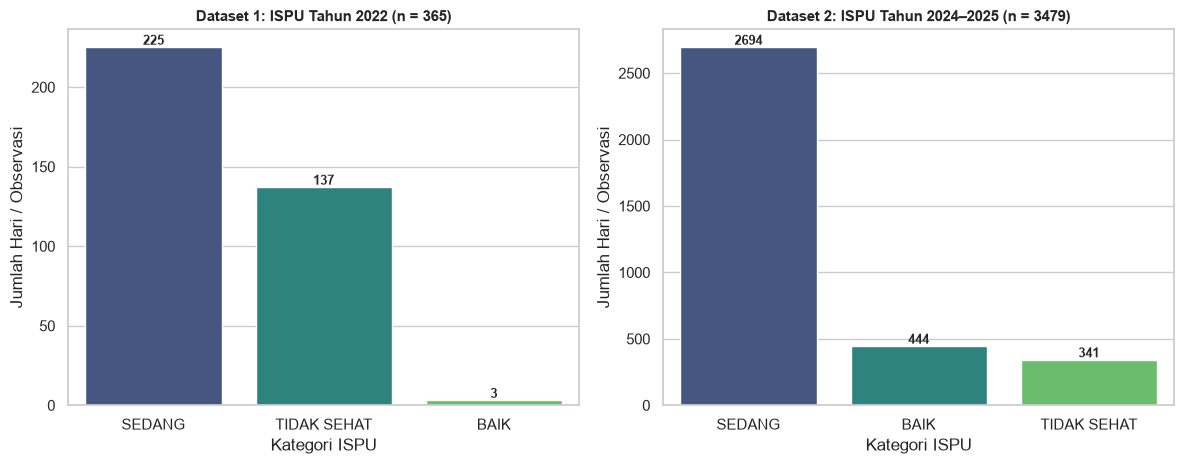

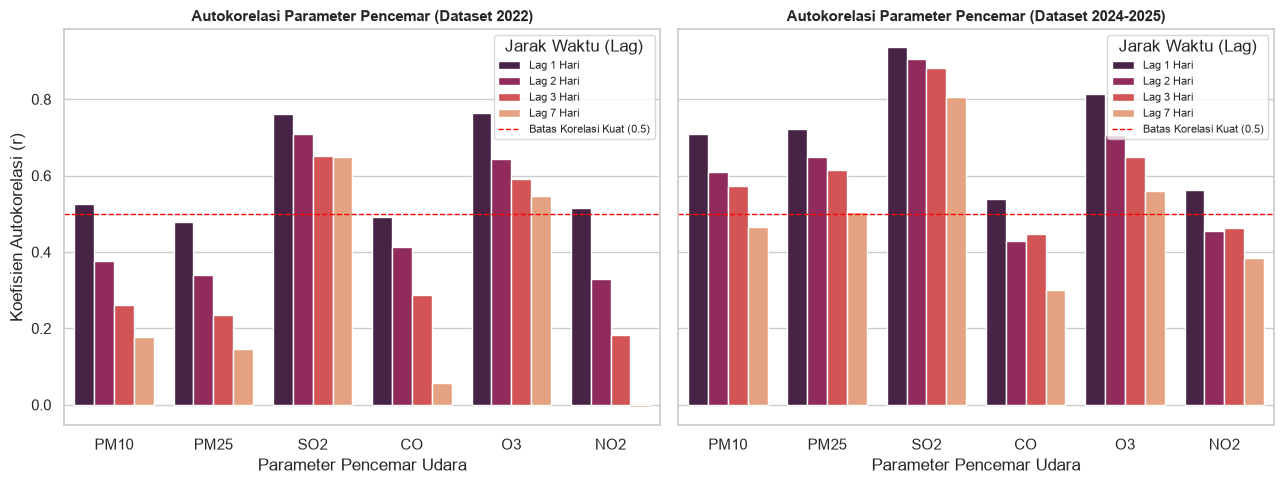

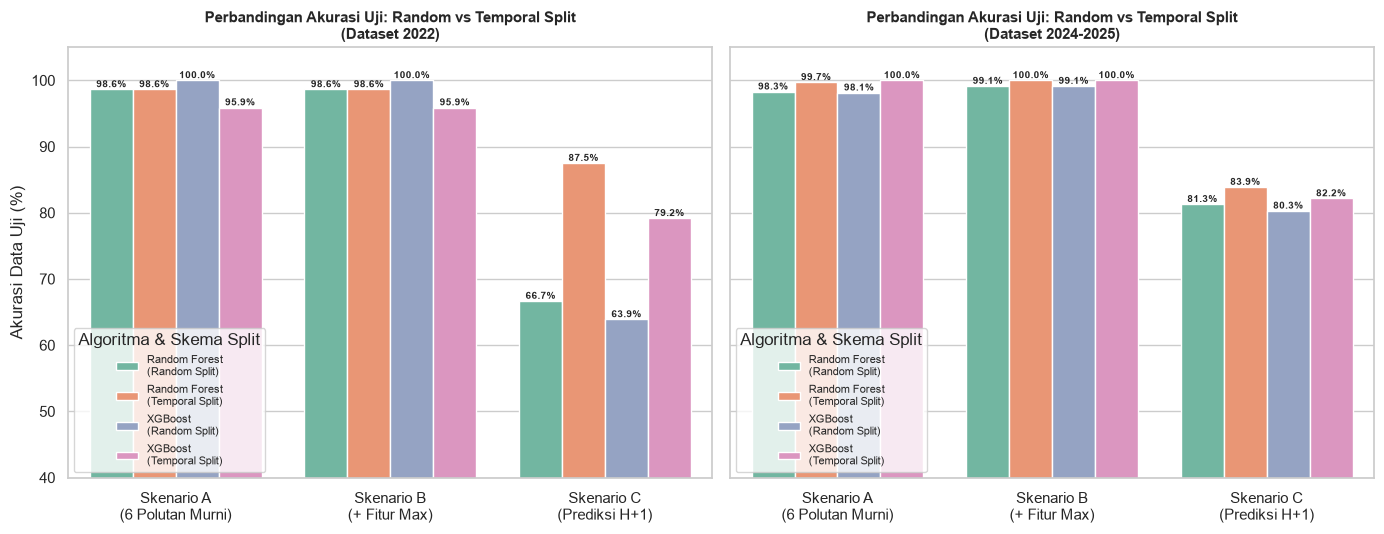

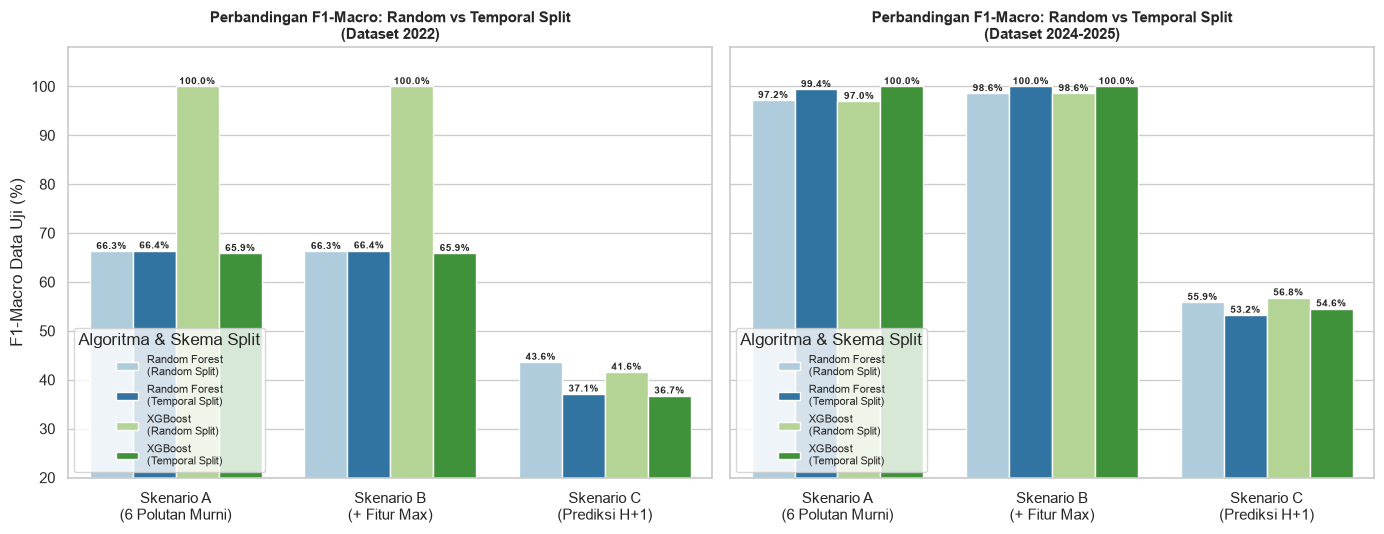

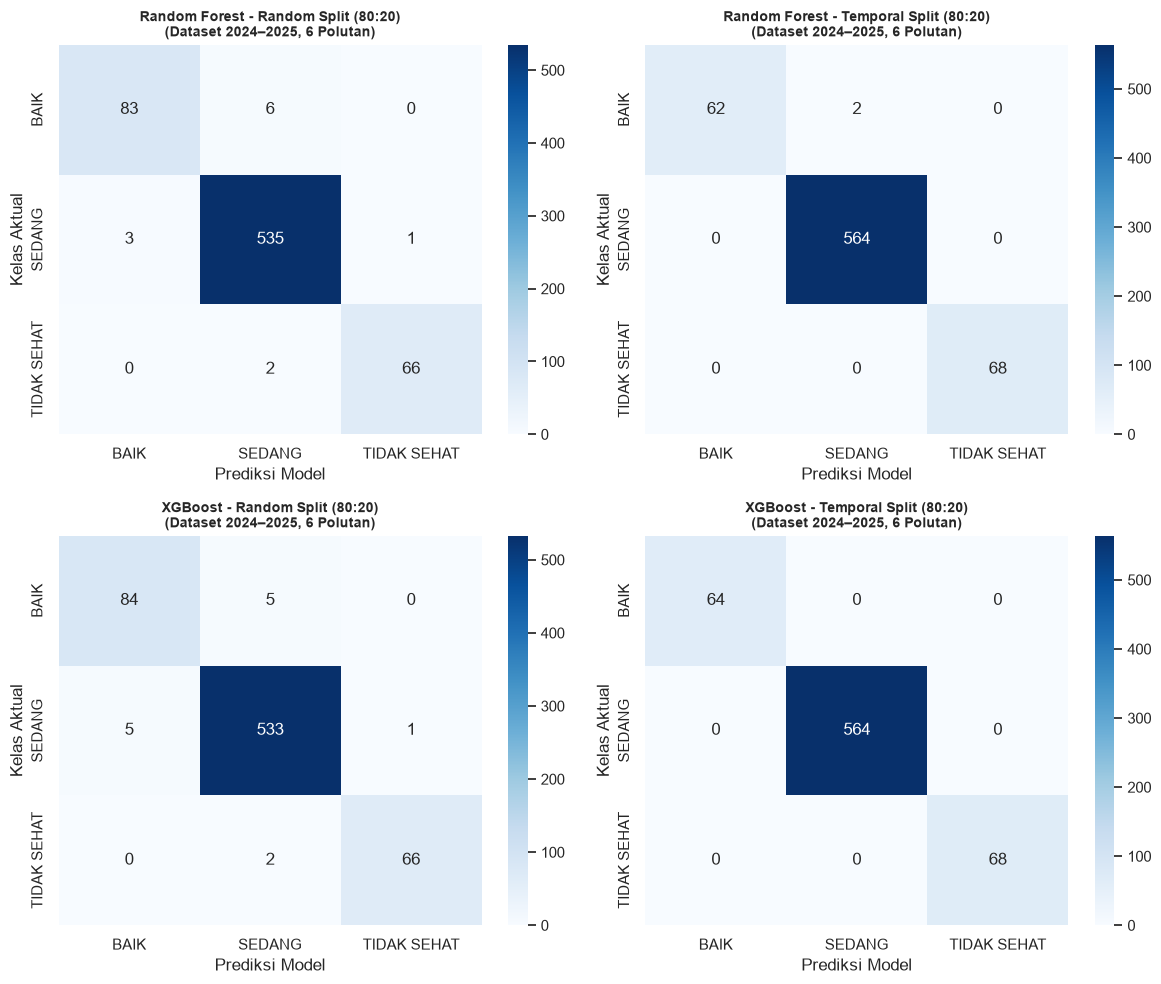


Seluruh grafik visualisasi berhasil disimpan di folder 'hasil_eksperimen/'.


In [10]:
cm_all = {**cm_2022, **cm_2024}
generate_visualizations(df_2022, df_2024, autocorr_df, results_df, cm_all)

## Langkah 10 – Simpan semua hasil ke CSV

In [11]:
df_2022.to_csv(os.path.join(OUTPUT_DIR, 'dataset_2022_cleaned.csv'), index=False)
df_2024.to_csv(os.path.join(OUTPUT_DIR, 'dataset_2024_2025_cleaned.csv'), index=False)
autocorr_df.to_csv(os.path.join(OUTPUT_DIR, 'hasil_autokorelasi.csv'), index=False)
results_df.to_csv(os.path.join(OUTPUT_DIR, 'hasil_evaluasi_lengkap.csv'), index=False)
pivot_df.to_csv(os.path.join(OUTPUT_DIR, 'selisih_kinerja_split.csv'))
print('Semua hasil tersimpan di folder:', os.path.abspath(OUTPUT_DIR))
print(os.listdir(OUTPUT_DIR))

Semua hasil tersimpan di folder: d:\Tugas Kuliah\Semester 5\PENAMBANGAN DATA\hasil_eksperimen
['1_distribusi_kelas_ispu.png', '2_autokorelasi_temporal.png', '3_perbandingan_akurasi_split.png', '4_perbandingan_f1_macro_split.png', '5_confusion_matrix_2024_2025.png', 'dataset_2022_cleaned.csv', 'dataset_2024_2025_cleaned.csv', 'hasil_autokorelasi.csv', 'hasil_evaluasi_lengkap.csv', 'selisih_kinerja_split.csv']
